# The Evolution of NLP: Comparing Three Eras of Sentiment Analysis
**Course:** Natural Language Processing | **Dataset:** NLTK Movie **Student:** Kashika Arora | **Roll number:** 2025EM1200130    Reviews (2,000 reviews, balanced pos/neg)

**Client question:** build a lightweight statistical model, invest in deep learning, or use an off-the-shelf pretrained model?

We run **three pipelines on the exact same 80/20 split** and compare accuracy, F1 and time cost.

| Pipeline | Approach | Trained by us? |
|---|---|---|
| 1 | TF-IDF + Logistic Regression | Yes |
| 2 | PyTorch `nn.Embedding` + BiLSTM | Yes |
| 3 | NLTK VADER (pretrained lexicon model) | No (zero-shot) |

In [1]:
import re, time, json, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import movie_reviews, stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, classification_report
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

for pkg in ['movie_reviews', 'stopwords', 'vader_lexicon']:
    nltk.download(pkg, quiet=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(1) if torch.get_num_threads() < 1 else None
RESULTS = {}   # collects metrics + timings for the final comparison

## Task 1: Data Sourcing & Preprocessing

In [2]:
# Load raw reviews: each file id is one review; its category (pos/neg) is the label
fileids = movie_reviews.fileids()
raw_texts = [movie_reviews.raw(f) for f in fileids]
labels = np.array([1 if movie_reviews.categories(f)[0] == 'pos' else 0 for f in fileids])

df = pd.DataFrame({'fileid': fileids, 'raw': raw_texts, 'label': labels})
df['n_words_raw'] = df['raw'].str.split().str.len()
print('Reviews:', len(df)); print(df['label'].value_counts().rename({1:'positive',0:'negative'}))
print('Avg words/review: %.0f (min %d, max %d)' % (df.n_words_raw.mean(), df.n_words_raw.min(), df.n_words_raw.max()))
print('\nSample review:\n', df.raw[0][:300], '...')

Reviews: 2000
label
negative    1000
positive    1000
Name: count, dtype: int64
Avg words/review: 746 (min 17, max 2678)

Sample review:
 plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
what's the deal ? 
watch the movie and " sorta " find out . . . 
critique : a mind-fuck movie for the ...


In [3]:
# Stop-word list: we KEEP negations (not, no, nor...) because they flip sentiment ("not good")
NEGATIONS = {'no', 'nor', 'not', "don't", "didn't", "doesn't", "isn't", "wasn't", "weren't", "aren't",
             "couldn't", "wouldn't", "shouldn't", "won't", "can't", "haven't", "hasn't", "hadn't", 'never'}
STOP = set(stopwords.words('english')) - NEGATIONS

def clean_text(text):
    """Preprocess one review:
    1. lowercase  2. strip URLs / HTML tags  3. expand "n't" so negation survives punctuation removal
    4. drop digits & punctuation (keep letters only)  5. drop stop-words and 1-2 letter tokens.
    Returns a space-joined string of tokens."""
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+|<[^>]+>', ' ', text)
    text = re.sub(r"n't\b", ' not', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = [t for t in text.split() if t not in STOP and len(t) > 2]
    return ' '.join(tokens)

df['clean'] = df['raw'].apply(clean_text)
df['n_words_clean'] = df['clean'].str.split().str.len()
print('Avg words after cleaning: %.0f' % df.n_words_clean.mean())
print('\nBefore:', df.raw[0][:150].replace('\n',' '))
print('After :', df.clean[0][:150])

Avg words after cleaning: 353

Before: plot : two teen couples go to a church party , drink and then drive .  they get into an accident .  one of the guys dies , but his girlfriend continue
After : plot two teen couples church party drink drive get accident one guys dies girlfriend continues see life nightmares deal watch movie sorta find critiqu


In [4]:
# ONE shared stratified 80/20 split, defined on row indices so every pipeline uses identical reviews.
idx = np.arange(len(df))
train_idx, test_idx = train_test_split(idx, test_size=0.20, random_state=SEED, stratify=df['label'])

train_df, test_df = df.iloc[train_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
y_train, y_test = train_df['label'].values, test_df['label'].values
print('Train:', len(train_df), '| Test:', len(test_df))
print('Test class balance (pos share): %.2f' % y_test.mean())
assert set(train_df.fileid).isdisjoint(set(test_df.fileid))   # no leakage

Train: 1600 | Test: 400
Test class balance (pos share): 0.50


## Task 2: Pipeline 1 – Traditional ML (TF-IDF + Logistic Regression)

In [5]:
def report(name, y_true, y_pred):
    """Compute accuracy + F1 (+ precision/recall) and store in RESULTS."""
    m = dict(accuracy=accuracy_score(y_true, y_pred), f1=f1_score(y_true, y_pred),
             precision=precision_score(y_true, y_pred), recall=recall_score(y_true, y_pred),
             cm=confusion_matrix(y_true, y_pred).tolist())
    RESULTS.setdefault(name, {}).update(m)
    print(f'{name}: accuracy={m["accuracy"]:.4f}  F1={m["f1"]:.4f}  precision={m["precision"]:.4f}  recall={m["recall"]:.4f}')
    print(classification_report(y_true, y_pred, target_names=['negative','positive'], digits=3))

t0 = time.perf_counter()
# Vectorizer is fit on TRAIN ONLY (no test vocabulary leaks in). Unigrams + bigrams capture "not good".
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)
X_train = tfidf.fit_transform(train_df['clean'])
clf = LogisticRegression(C=10, max_iter=1000, random_state=SEED)
clf.fit(X_train, y_train)
ml_train_time = time.perf_counter() - t0          # vectorising + fitting

t0 = time.perf_counter()
ml_pred = clf.predict(tfidf.transform(test_df['clean']))
ml_infer_time = time.perf_counter() - t0
RESULTS['TF-IDF + LogReg'] = dict(train_time=ml_train_time, infer_time=ml_infer_time, params=int(clf.coef_.size))
print(f'Features: {X_train.shape[1]:,} | train time {ml_train_time:.2f}s | inference {ml_infer_time:.3f}s\n')
report('TF-IDF + LogReg', y_test, ml_pred)

Features: 34,752 | train time 4.10s | inference 0.587s

TF-IDF + LogReg: accuracy=0.8500  F1=0.8544  precision=0.8302  recall=0.8800
              precision    recall  f1-score   support

    negative      0.872     0.820     0.845       200
    positive      0.830     0.880     0.854       200

    accuracy                          0.850       400
   macro avg      0.851     0.850     0.850       400
weighted avg      0.851     0.850     0.850       400



In [6]:
# Interpretability bonus: the words the model finds most predictive
fn = np.array(tfidf.get_feature_names_out()); order = np.argsort(clf.coef_[0])
print('Most NEGATIVE:', ', '.join(fn[order[:12]]))
print('Most POSITIVE:', ', '.join(fn[order[-12:]][::-1]))

Most NEGATIVE: bad, worst, nothing, boring, supposed, script, plot, ridiculous, mess, unfortunately, looks, not even
Most POSITIVE: great, well, perfect, hilarious, excellent, also, overall, fun, terrific, life, perfectly, memorable


## Task 3: Pipeline 2 – Deep Learning (PyTorch Embedding + BiLSTM)
Words → integer ids → `nn.Embedding` (learned from scratch) → bidirectional LSTM → dense layer → sigmoid. A 10% slice of the *training* set is held out for validation/early stopping, so the test set is never used to tune the network.

In [7]:
# --- Vocabulary built from TRAINING reviews only ---
from collections import Counter
MAX_LEN, MIN_FREQ = 400, 2
counts = Counter(w for doc in train_df['clean'] for w in doc.split())
itos = ['<pad>', '<unk>'] + [w for w, c in counts.items() if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
print('Vocabulary size:', len(itos))

def encode(doc):
    ids = [stoi.get(w, 1) for w in doc.split()][:MAX_LEN]      # unknown words -> <unk>, truncate long reviews
    return ids + [0] * (MAX_LEN - len(ids))                    # pad short ones

to_tensor = lambda s: torch.tensor([encode(d) for d in s], dtype=torch.long)
Xtr_all, Xte = to_tensor(train_df['clean']), to_tensor(test_df['clean'])
ytr_all, yte = torch.tensor(y_train, dtype=torch.float32), torch.tensor(y_test, dtype=torch.float32)

# validation slice carved out of the training set
tr_i, va_i = train_test_split(np.arange(len(Xtr_all)), test_size=0.10, random_state=SEED, stratify=y_train)
train_loader = DataLoader(TensorDataset(Xtr_all[tr_i], ytr_all[tr_i]), batch_size=32, shuffle=True)
Xva, yva = Xtr_all[va_i], ytr_all[va_i]
print('DL train/val/test sizes:', len(tr_i), len(va_i), len(Xte))

Vocabulary size: 22651
DL train/val/test sizes: 1440 160 400


In [8]:
class LSTMSentiment(nn.Module):
    def __init__(self, vocab_size, emb_dim=64, hidden=64, dropout=0.5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)   # dense word vectors, learned from scratch
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * 2, 1)
    def forward(self, x):
        mask = (x != 0).unsqueeze(-1).float()
        out, _ = self.lstm(self.drop(self.embedding(x)))                  # (B, T, 2H)
        pooled = (out * mask).sum(1) / mask.sum(1).clamp(min=1)           # masked mean-pool over real tokens
        return self.fc(self.drop(pooled)).squeeze(-1)                     # logit

model = LSTMSentiment(len(itos))
n_params = sum(p.numel() for p in model.parameters())
print(model); print(f'Trainable parameters: {n_params:,}')

def predict(model, X, bs=128):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append((torch.sigmoid(model(X[i:i+bs])) > 0.5).int())
    return torch.cat(out).numpy()

LSTMSentiment(
  (embedding): Embedding(22651, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True, bidirectional=True)
  (drop): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)
Trainable parameters: 1,516,353


In [9]:
EPOCHS, PATIENCE = 12, 3
opt = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-5)
loss_fn = nn.BCEWithLogitsLoss()
best_val, best_state, bad, history = 0, None, 0, []

t0 = time.perf_counter()
for ep in range(1, EPOCHS + 1):
    model.train(); tot = 0
    for xb, yb in train_loader:
        opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); tot += loss.item() * len(xb)
    val_acc = accuracy_score(yva.numpy(), predict(model, Xva))
    history.append((tot / len(tr_i), val_acc))
    print(f'epoch {ep:2d} | train loss {history[-1][0]:.4f} | val acc {val_acc:.3f}')
    if val_acc > best_val: best_val, bad, best_state = val_acc, 0, {k: v.clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
        if bad >= PATIENCE: print('early stopping'); break
dl_train_time = time.perf_counter() - t0
model.load_state_dict(best_state)                                          # restore best epoch
print(f'\nTraining time: {dl_train_time:.1f}s')

epoch  1 | train loss 0.6931 | val acc 0.575
epoch  2 | train loss 0.6871 | val acc 0.556
epoch  3 | train loss 0.6522 | val acc 0.656
epoch  4 | train loss 0.5235 | val acc 0.594
epoch  5 | train loss 0.4096 | val acc 0.644
epoch  6 | train loss 0.3227 | val acc 0.688
epoch  7 | train loss 0.2653 | val acc 0.744
epoch  8 | train loss 0.1884 | val acc 0.725
epoch  9 | train loss 0.1331 | val acc 0.694
epoch 10 | train loss 0.0845 | val acc 0.706
early stopping

Training time: 145.4s


In [10]:
t0 = time.perf_counter(); dl_pred = predict(model, Xte); dl_infer_time = time.perf_counter() - t0
RESULTS['BiLSTM (PyTorch)'] = dict(train_time=dl_train_time, infer_time=dl_infer_time, params=n_params)
report('BiLSTM (PyTorch)', y_test, dl_pred)

BiLSTM (PyTorch): accuracy=0.7325  F1=0.7738  precision=0.6703  recall=0.9150
              precision    recall  f1-score   support

    negative      0.866     0.550     0.673       200
    positive      0.670     0.915     0.774       200

    accuracy                          0.733       400
   macro avg      0.768     0.733     0.723       400
weighted avg      0.768     0.733     0.723       400



## Task 4: Pipeline 3 – Pretrained Model (NLTK VADER, zero-shot)
VADER is a rule/lexicon-based sentiment model built for **social-media text** (tweets, short posts). **No training happens here.** We pass test reviews through it and turn the `compound` score (−1…+1) into a binary label: `>= 0` → positive, else negative.

In [11]:
from nltk.sentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

def vader_label(text, thr=0.0):
    return int(sia.polarity_scores(text)['compound'] >= thr)

# VADER uses capitalisation, punctuation and negation rules, so it gets the RAW review text (not our cleaned text).
t0 = time.perf_counter()
vader_pred = np.array([vader_label(t) for t in test_df['raw']])
vader_infer_time = time.perf_counter() - t0
RESULTS['VADER (pretrained)'] = dict(train_time=0.0, infer_time=vader_infer_time, params=0)
report('VADER (pretrained)', y_test, vader_pred)

# Diagnostic: how often does VADER say "positive"? (domain-shift check)
print(f'VADER predicts positive for {vader_pred.mean():.0%} of test reviews (true share: {y_test.mean():.0%})')
print(f'Mean compound score by true class:', test_df.assign(c=[sia.polarity_scores(t)["compound"] for t in test_df.raw]).groupby('label').c.mean().round(3).to_dict())

VADER (pretrained): accuracy=0.6475  F1=0.6968  precision=0.6113  recall=0.8100
              precision    recall  f1-score   support

    negative      0.719     0.485     0.579       200
    positive      0.611     0.810     0.697       200

    accuracy                          0.647       400
   macro avg      0.665     0.647     0.638       400
weighted avg      0.665     0.647     0.638       400

VADER predicts positive for 66% of test reviews (true share: 50%)
Mean compound score by true class: {0: 0.056, 1: 0.621}


## Side-by-side comparison

,Accuracy,F1,Precision,Recall,Train time (s),Test inference (s),Parameters
TF-IDF + LogReg,0.85,0.854369,0.830189,0.88,4.095202,0.586981,34752
BiLSTM (PyTorch),0.7325,0.773784,0.67033,0.915,145.408704,1.251878,1516353
VADER (pretrained),0.6475,0.696774,0.611321,0.81,0.0,3.077135,0


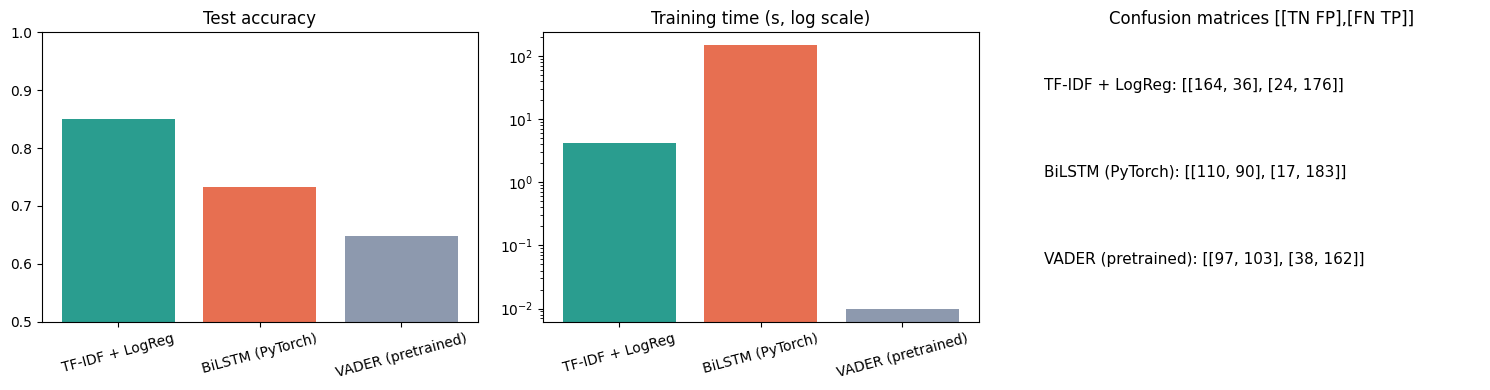

In [12]:
res = pd.DataFrame(RESULTS).T[['accuracy','f1','precision','recall','train_time','infer_time','params']]
res.columns = ['Accuracy','F1','Precision','Recall','Train time (s)','Test inference (s)','Parameters']
display(res.round(4))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
names = list(RESULTS)
ax[0].bar(names, [RESULTS[n]['accuracy'] for n in names], color=['#2a9d8f','#e76f51','#8d99ae']); ax[0].set_ylim(0.5, 1); ax[0].set_title('Test accuracy')
ax[1].bar(names, [max(RESULTS[n]['train_time'], 1e-2) for n in names], color=['#2a9d8f','#e76f51','#8d99ae']); ax[1].set_yscale('log'); ax[1].set_title('Training time (s, log scale)')
for a in ax[:2]: a.tick_params(axis='x', rotation=15)
cms = np.array([RESULTS[n]['cm'] for n in names])
ax[2].axis('off'); ax[2].set_title('Confusion matrices [[TN FP],[FN TP]]')
for i, n in enumerate(names): ax[2].text(0, 0.8 - i * 0.3, f'{n}: {cms[i].tolist()}', fontsize=11)
plt.tight_layout(); plt.show()
json.dump(RESULTS, open('results.json', 'w'), indent=2)

## Summary (feeds Task 5 presentation)
See the accompanying presentation for the full business analysis: metric comparison, why the pretrained model under-performed (domain shift: social-media lexicon vs long-form film criticism), metric choice (accuracy + F1, supported by confusion matrices), and the deployment recommendation.